# Kunci Lab 5: Deret Waktu dan Data Panel



**Pengayaan pilihan:** pengujian ramalan inflasi Indonesia (30 sampai 40 menit). Waktu ini di luar durasi materi inti.

## Persiapan: alamat data

Jalankan sel alamat data dan instalasi `linearmodels` dengan koneksi internet.



**Alur sesi:** kita menggunakan urutan waktu dan pengamatan berulang. Mulai dari tabel **Kenali data**, amati grafik, jalankan model, lalu jelaskan hasilnya dengan kata sendiri. Fokus visual sesi ini adalah perbedaan data aktual, ramalan, dan pola antarunit.

In [1]:
URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

print("Alamat data siap. Jalankan sel pembacaan CSV berikutnya.")


Alamat data siap. Jalankan sel pembacaan CSV berikutnya.


In [2]:
%pip install "linearmodels==7.1" -q


Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import statsmodels.api as sm



import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "legend.fontsize": 10})


## Latihan 1: ADF dan ARIMA untuk saham



<!-- kamus_variabel:ts_saham.csv -->

### Kenali data: Harga saham simulasi

**Data:** `data/ts_saham.csv`. **Satu baris:** satu urutan periode simulasi; bukan tanggal kalender.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `obs` | Urutan waktu pengamatan. | 1, 2, 3, ...; frekuensi kalender tidak dirinci | Penanda waktu |
| `saham` | Deret harga saham simulasi untuk uji stasioneritas dan peramalan. | Level harga; skala uang tidak dirinci | Deret yang dianalisis |

Nomor obs tidak menunjukkan tanggal/bulan/tahun tertentu. Angka level dan perubahan persennya harus dibedakan.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [4]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA

saham_ts = pd.read_csv(URL_DATA + "ts_saham.csv")

saham_ts.head()

,obs,saham
0,1,5000
1,2,5050
2,3,5025
3,4,5100
4,5,5080


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [5]:
print("ADF level       :", round(adfuller(saham_ts["saham"])[1], 4))
print("ADF selisih     :", round(adfuller(saham_ts["saham"].diff().dropna())[1], 4))

model_saham = ARIMA(saham_ts["saham"], order=(1, 1, 0)).fit()
ramalan = model_saham.get_forecast(steps=5).predicted_mean
print("Ramalan 5 periode:", np.round(np.asarray(ramalan), 1).tolist())

ADF level       : 0.9763
ADF selisih     : 0.0
Ramalan 5 periode: [5787.6, 5787.4, 5787.4, 5787.4, 5787.4]


C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_24460\2792152063.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("ADF level       :", round(adfuller(saham_ts["saham"])[1], 4))
C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_24460\2792152063.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("ADF selisih     :", round(adfuller(saham_ts["saham"].diff().dropna

### Lihat rentang data yang dipakai meramal

Garis putus-putus dimulai setelah pengamatan terakhir. Bagian ramalan tidak diperlakukan sebagai data aktual.

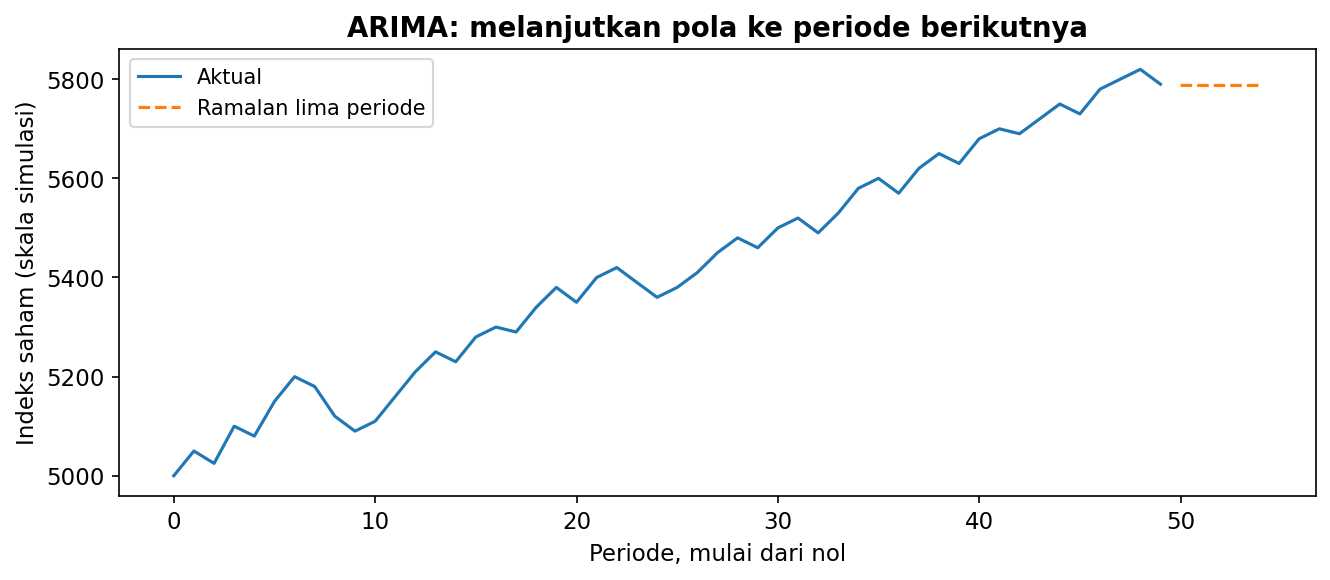

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(saham_ts.index, saham_ts["saham"], label="Aktual")
ax.plot(ramalan.index, ramalan, "--", label="Ramalan lima periode")
ax.set_xlabel("Periode, mulai dari nol")
ax.set_ylabel("Indeks saham (skala simulasi)")
ax.set_title("ARIMA: melanjutkan pola ke periode berikutnya")
ax.legend()
plt.tight_layout()
plt.show()

**Cara membaca:** Ini ramalan titik dari contoh ARIMA, bukan jaminan harga yang akan terjadi. Cocokkan perubahan level dengan hasil uji stasioneritas yang dicetak sebelumnya.

Kesimpulan: saham tidak stasioner di level (p = 0,98) dan stasioner
setelah selisih (p = 0,0000), khas random walk. Ramalan ARIMA(1,1,0)
hampir datar di sekitar 5.787: wajar, karena random walk tidak bisa
diprediksi arahnya.



## Latihan 2: kointegrasi IHSG dan emas



<!-- kamus_variabel:ihsg_emas.csv -->

### Kenali data: IHSG dan harga emas simulasi

**Data:** `data/ihsg_emas.csv`. **Satu baris:** satu bulan berurutan pada contoh simulasi.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Bulan` | Urutan bulan pengamatan. | Nomor bulan; tanggal kalender tidak dicantumkan | Penanda waktu |
| `IHSG_Y` | Indeks Harga Saham Gabungan dalam contoh simulasi. | Poin indeks | Y: target |
| `Emas_X` | Harga emas pada contoh simulasi. | Mata uang dan berat acuan tidak dirinci | X: penjelas |

Tabel ini adalah contoh simulasi; berbeda dari data IHSG harian unduhan Yahoo Finance.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [7]:
from statsmodels.tsa.stattools import coint

ie = pd.read_csv(URL_DATA + "ihsg_emas.csv")

ie.head()

,Bulan,IHSG_Y,Emas_X
0,1,4500.10,1500.5
1,2,4520.25,1510.2
2,3,4480.15,1525.4
3,4,4495.30,1515.8
4,5,4550.60,1490.2


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [8]:
p_kointe = coint(ie["IHSG_Y"], ie["Emas_X"])[1]
print("Uji kointegrasi: p =", round(p_kointe, 4))

Uji kointegrasi: p = 0.4941


### Dua seri yang bergerak bersama belum tentu berkointegrasi

Kedua seri menggunakan skala berbeda, sehingga ditampilkan terpisah dengan sumbu waktu bersama.

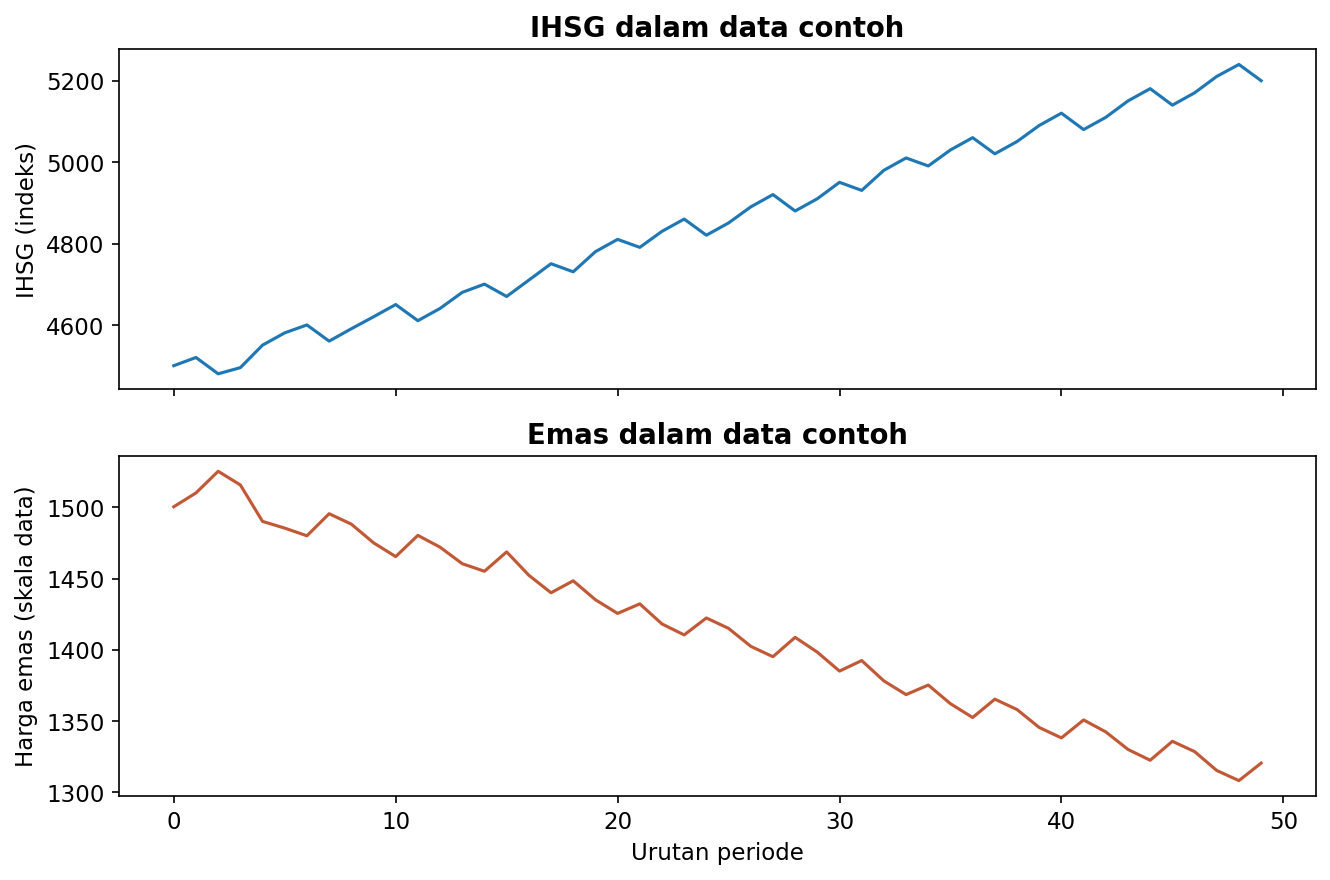

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(ie["IHSG_Y"])
axes[0].set(ylabel="IHSG (indeks)", title="IHSG dalam data contoh")
axes[1].plot(ie["Emas_X"], color="#C15937")
axes[1].set(xlabel="Urutan periode", ylabel="Harga emas (skala data)", title="Emas dalam data contoh")
plt.tight_layout()
plt.show()

**Cara membaca:** Kemiripan arah garis membantu mengajukan pertanyaan. Keputusan kointegrasi tetap mengikuti pemeriksaan orde integrasi dan uji Engle–Granger.

Kesimpulan: p = 0,4941, jauh di atas 0,05. IHSG dan emas TIDAK
terkointegrasi. Walaupun dua-duanya bergerak sepanjang waktu, tidak ada
hubungan jangka panjang yang mengikat. Karena itu ECM tidak layak
dipakai di kasus ini. Bandingkan dengan konsumsi-pendapatan
(p coint = 0,0001). Pada konsumsi-pendapatan, ADF log di level justru
menolak akar unit; karena itu ECM di sana hanya demonstrasi perhitungan,
bukan bukti empiris kointegrasi yang memenuhi syarat I(1).



## Latihan 3: panel retail CEM vs FEM



<!-- kamus_variabel:panel_retail.csv -->

### Kenali data: Panel toko ritel

**Data:** `data/panel_retail.csv`. **Satu baris:** satu cabang toko pada satu bulan.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `StoreID` | Kode cabang toko. | Nomor identitas toko | Penanda, bukan besaran ekonomi |
| `Month` | Urutan bulan dalam panel. | Bulan ke-1, ke-2, ... | Penanda waktu |
| `Sales_Y` | Besarnya penjualan toko pada bulan tersebut. | Satuan/skala tidak dirinci sumber | Y: target |
| `Ads_X1` | Biaya iklan cabang toko. | Satuan/skala tidak dirinci sumber | X: penjelas |
| `Discount_X2` | Proporsi potongan harga. | Pecahan; 0,10 berarti diskon 10% | X: penjelas |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [10]:
from linearmodels.panel import PanelOLS

retail = pd.read_csv(URL_DATA + "panel_retail.csv")

retail.head()

,StoreID,Month,Sales_Y,Ads_X1,Discount_X2
0,1,1,100.5,5.2,0.10
1,1,2,102.3,5.5,0.10
2,1,3,110.5,6.0,0.15
3,1,4,108.2,5.8,0.12
4,1,5,120.1,7.0,0.20


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [11]:
retail = retail.set_index(["StoreID", "Month"])
y = retail["Sales_Y"]
X = retail[["Ads_X1", "Discount_X2"]]

cem = PanelOLS(y, sm.add_constant(X)).fit()
fem = PanelOLS(y, X, entity_effects=True).fit()

print("CEM:")
print(cem.params.round(3))
print("\nFEM:")
print(fem.params.round(3))

CEM:
const           22.430
Ads_X1          18.836
Discount_X2   -157.069
Name: parameter, dtype: float64

FEM:
Ads_X1         11.060
Discount_X2    -1.939
Name: parameter, dtype: float64


### Bandingkan penjualan beberapa toko dari waktu ke waktu

Satu toko dapat mempunyai tingkat penjualan yang konsisten berbeda dari toko lain.

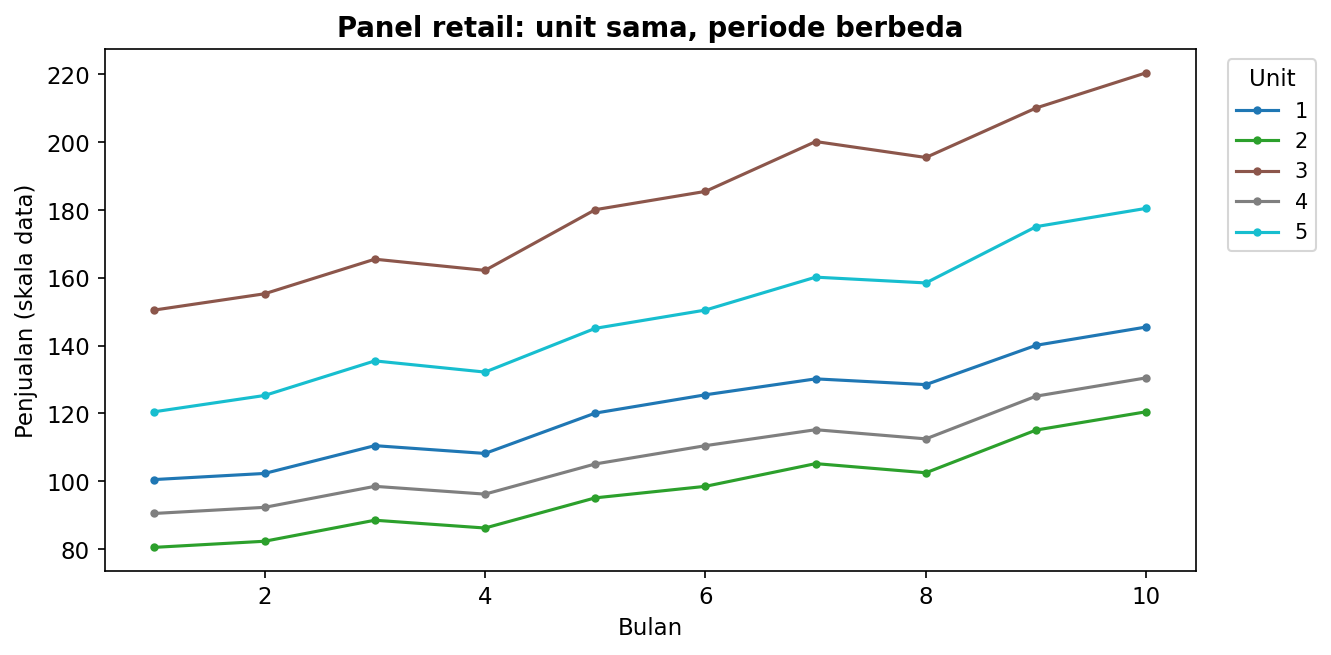

In [12]:
tabel_garis = retail.reset_index().pivot(index="Month", columns="StoreID", values="Sales_Y")
ax = tabel_garis.plot(colormap="tab10", figsize=(9, 4.5), marker="o", markersize=3)
ax.set_xlabel("Bulan")
ax.set_ylabel("Penjualan (skala data)")
ax.set_title("Panel retail: unit sama, periode berbeda")
ax.legend(title="Unit", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** Perbedaan tingkat antartoko menjadi salah satu alasan mempertimbangkan efek individu. Setelah membaca grafik, bandingkan koefisien CEM dan FEM pada tabel.

Kesimpulan: di CEM, koefisien diskon -157 (signifikan) karena model
mencampur perbedaan antar toko: toko beromzet tinggi kebetulan juga
memberi diskon besar. Setelah efek toko dikontrol (FEM), koefisien
diskon hanya -1,9 dan tidak signifikan. Untuk kebijakan diskon, yang
relevan adalah perubahan DI DALAM toko yang sama, jadi FEM lebih
dipercaya. Uji Chow p-value sangat kecil, mendukung FEM.


## Pengayaan: apakah ramalan inflasi mengalahkan tebakan sederhana? (30 sampai 40 menit)

Model yang cocok dengan masa lalu belum tentu meramal dengan baik.
Kita akan menguji **ramalan inflasi YoY satu bulan ke depan**, menggunakan
data Indonesia yang sudah tersedia. Periode uji belum dipakai untuk melatih model.

Data bersumber dari seri IHK OECD melalui FRED; inflasi dihitung dari perubahan
indeks pada salinan tutorial. Berkas berakhir April 2025, sehingga contoh ini
merupakan pengujian historis, bukan pembaruan inflasi terkini.

<!-- kamus_variabel:idn_inflasi_bulanan.csv -->

### Kenali data: IHK dan inflasi Indonesia bulanan

**Data:** `data/idn_inflasi_bulanan.csv`. **Satu baris:** satu bulan kalender.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `tanggal` | Bulan pengamatan; tanggal berfungsi sebagai penanda bulan. | Tanggal YYYY-MM-DD | Penanda waktu |
| `indeks` | Indeks Harga Konsumen (IHK), yaitu ukuran tingkat harga keranjang konsumsi. | Poin indeks; tahun dasar mengikuti seri sumber | Level harga |
| `inflasi_mom` | Persentase perubahan indeks dari bulan sebelumnya (month-on-month). | 100 × (indeks bulan ini / bulan lalu - 1) | Deret yang dianalisis |
| `inflasi_yoy` | Persentase perubahan indeks dari bulan yang sama setahun sebelumnya (year-on-year). | 100 × (indeks bulan ini / indeks 12 bulan lalu - 1) | Deret yang dianalisis |

indeks adalah level, sedangkan inflasi_mom dan inflasi_yoy adalah perubahan persen yang dihitung oleh skrip unduhan. Angka 2 pada kolom inflasi berarti 2%, bukan 0,02%.

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada CSV awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `lag_1` | Inflasi YoY pada satu bulan sebelumnya; digunakan sebagai fitur ramalan. | Persen; dibuat dengan shift(1) |
| `lag_12` | Inflasi YoY pada bulan yang sama setahun sebelumnya; digunakan sebagai fitur ramalan. | Persen; dibuat dengan shift(12) |

Sumber definisi: [rujukan data](https://fred.stlouisfed.org/series/IDNCPIALLMINMEI).


In [13]:
inflasi_ramalan = pd.read_csv(URL_DATA + "idn_inflasi_bulanan.csv", parse_dates=["tanggal"])
inflasi_ramalan = inflasi_ramalan.sort_values("tanggal").set_index("tanggal")
inflasi_ramalan["lag_1"] = inflasi_ramalan["inflasi_yoy"].shift(1)
inflasi_ramalan["lag_12"] = inflasi_ramalan["inflasi_yoy"].shift(12)
inflasi_ramalan = inflasi_ramalan.loc["2010-01-01":].dropna(subset=["inflasi_yoy", "lag_1", "lag_12"])
inflasi_ramalan[["inflasi_yoy", "lag_1", "lag_12"]].head()

,inflasi_yoy,lag_1,lag_12
tanggal,,,
2010-01-01,3.717682,2.784117,8.238216
2010-02-01,3.823889,3.717682,7.759194
2010-03-01,3.430478,3.823889,6.974354
2010-04-01,3.906256,3.430478,6.041143
2010-05-01,4.158994,3.906256,4.617225


### 1. Gunakan informasi yang sudah diketahui

`shift(1)` mengambil inflasi bulan sebelumnya. `shift(12)` mengambil inflasi
pada bulan yang sama tahun sebelumnya. Untuk meramal inflasi bulan t, kedua
informasi itu sudah tersedia pada akhir bulan t-1 dalam contoh kalender ini.
Ini mengabaikan jeda publikasi; penggunaan operasional harus memperhitungkannya.
Kita tidak memakai inflasi bulan t sebagai fitur untuk meramal dirinya sendiri.

Latihan dimulai pada 2010 agar contoh tidak mencampurkan seluruh sejarah sejak 1969.
Data **2010 sampai 2023** dipakai untuk latihan dan validasi berurutan.
Data **Januari 2024 sampai April 2025** disimpan untuk pengujian terakhir.

`parse_dates` membaca kolom tanggal sebagai waktu, `sort_values` mengurutkannya,
dan `set_index` menjadikan tanggal sebagai penanda baris untuk memilih rentang waktu.

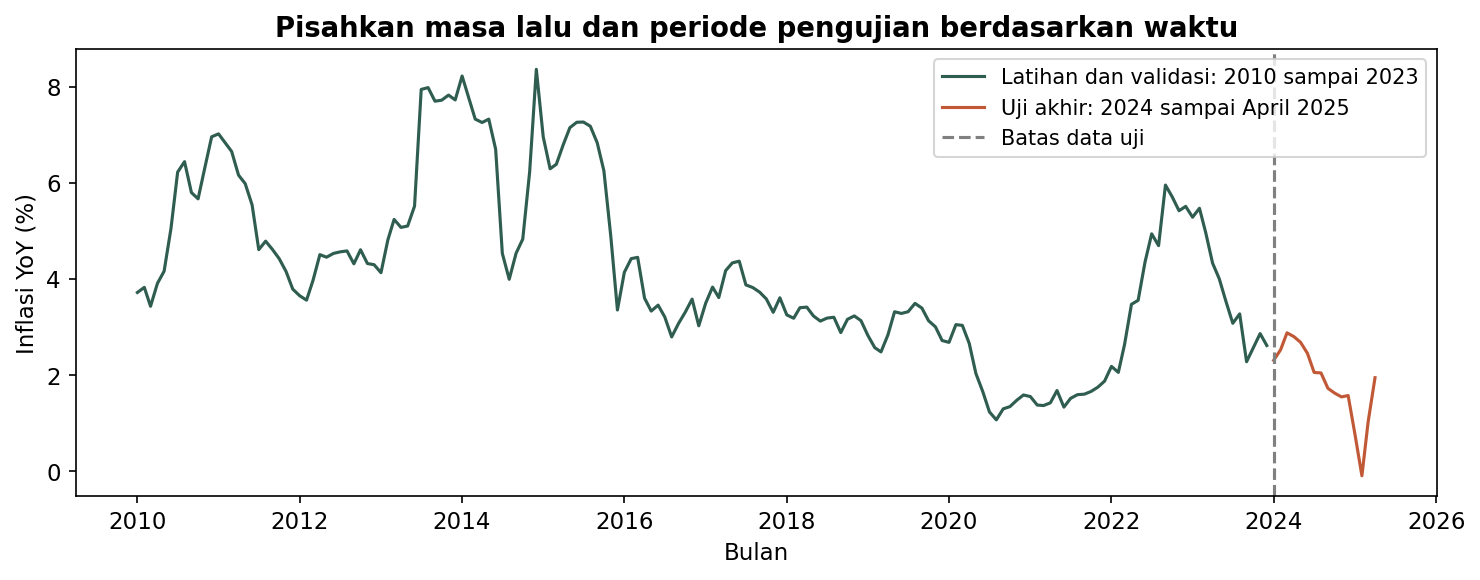

In [14]:
latih_ramalan = inflasi_ramalan.loc[:"2023-12-31"].copy()
uji_ramalan = inflasi_ramalan.loc["2024-01-01":].copy()
X_latih_ramalan = latih_ramalan[["lag_1", "lag_12"]]
y_latih_ramalan = latih_ramalan["inflasi_yoy"]
X_uji_ramalan = uji_ramalan[["lag_1", "lag_12"]]
y_uji_ramalan = uji_ramalan["inflasi_yoy"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(latih_ramalan.index, y_latih_ramalan, color="#2F5D50", label="Latihan dan validasi: 2010 sampai 2023")
ax.plot(uji_ramalan.index, y_uji_ramalan, color="#C15937", label="Uji akhir: 2024 sampai April 2025")
ax.axvline(pd.Timestamp("2024-01-01"), linestyle="--", color="gray", label="Batas data uji")
ax.set_xlabel("Bulan")
ax.set_ylabel("Inflasi YoY (%)")
ax.set_title("Pisahkan masa lalu dan periode pengujian berdasarkan waktu")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

**Cara membaca:** garis hijau mendahului garis jingga. Model boleh belajar dari
periode hijau; bagian jingga digunakan untuk menilai ramalan setelah rancangan
ditetapkan. Pembagian acak akan mencampurkan urutan ini.

### 2. Periksa tiga tahun validasi sebelum membuka hasil uji

`TimeSeriesSplit` membuat tiga pengujian berurutan, masing-masing 12 bulan.
Latihan bertambah dari satu pengujian ke pengujian berikutnya; seluruh periodenya
tetap sebelum 2024. Data kita berjarak satu bulan sehingga panjang jendelanya sebanding.

`cross_val_score` menjalankan pola latihan dan penilaian tersebut secara otomatis.
Tanda minus di depan mengubah keluaran `neg_mean_absolute_error` menjadi MAE positif.

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

pembagian_waktu_ramalan = TimeSeriesSplit(n_splits=3, test_size=12)
mae_validasi_ramalan = -cross_val_score(
    LinearRegression(), X_latih_ramalan, y_latih_ramalan,
    cv=pembagian_waktu_ramalan, scoring="neg_mean_absolute_error"
)
hasil_validasi_ramalan = pd.DataFrame({
    "tahun_validasi": [2021, 2022, 2023],
    "MAE_poin_persentase": mae_validasi_ramalan,
})
hasil_validasi_ramalan.round(3)

,tahun_validasi,MAE_poin_persentase
0,2021,0.151
1,2022,0.422
2,2023,0.403


MAE menyatakan rata-rata besar kesalahan tanpa memperhatikan arahnya.
MAE 0,4 berarti ramalan meleset rata-rata 0,4 **poin persentase**, bukan 40%.
Perbedaan MAE antarperiode memperlihatkan bahwa kesulitan meramal dapat berubah.

### 3. Latih model akhir, lalu bandingkan dengan ramalan naif

Model akhir belajar dari seluruh periode latihan sampai Desember 2023.
Ramalan naif menganggap inflasi bulan berikutnya sama dengan inflasi bulan terakhir.
Keduanya diuji pada bulan yang sama dengan informasi masa lalu yang sama.

In [16]:
model_ramalan = LinearRegression()
model_ramalan.fit(X_latih_ramalan, y_latih_ramalan)
prediksi_uji_ramalan = model_ramalan.predict(X_uji_ramalan)
prediksi_naif_ramalan = uji_ramalan["lag_1"]

from sklearn.metrics import mean_absolute_error, root_mean_squared_error

hasil_uji_ramalan = pd.DataFrame({
    "metode": ["Naif: sama dengan bulan lalu", "Regresi: lag 1 dan lag 12"],
    "MAE_poin_persentase": [
        mean_absolute_error(y_uji_ramalan, prediksi_naif_ramalan),
        mean_absolute_error(y_uji_ramalan, prediksi_uji_ramalan),
    ],
    "RMSE_poin_persentase": [
        root_mean_squared_error(y_uji_ramalan, prediksi_naif_ramalan),
        root_mean_squared_error(y_uji_ramalan, prediksi_uji_ramalan),
    ],
})
hasil_uji_ramalan.round(3)

,metode,MAE_poin_persentase,RMSE_poin_persentase
0,Naif: sama dengan bulan lalu,0.372,0.507
1,Regresi: lag 1 dan lag 12,0.419,0.522


### 4. Baca kesalahan pada bulan yang sama

RMSE memberi perhatian lebih besar pada kesalahan besar. Kita tidak memakai
persentase kesalahan relatif (MAPE), karena inflasi dapat mendekati nol atau negatif.

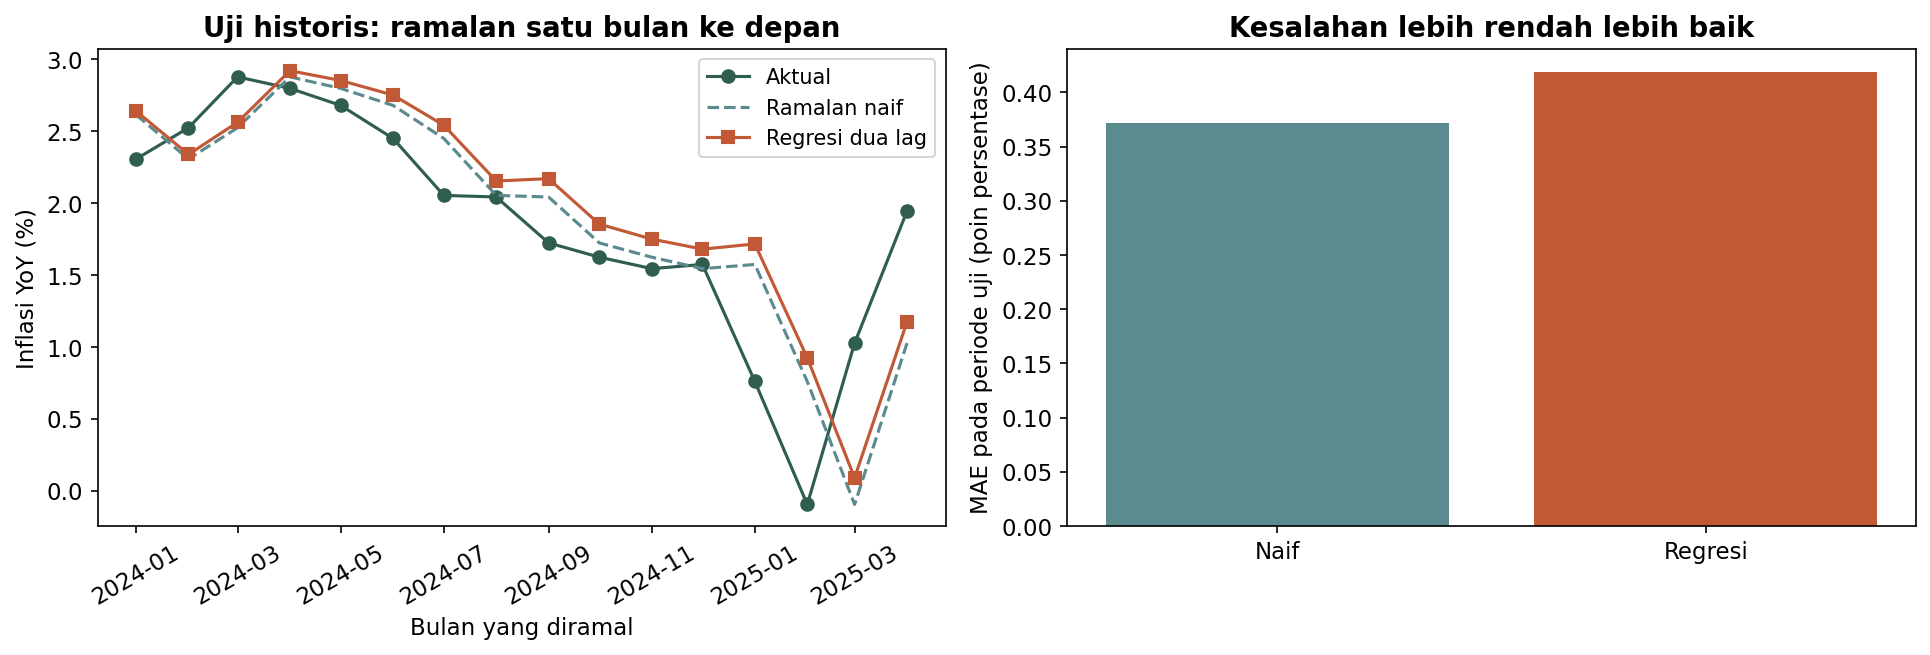

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(y_uji_ramalan.index, y_uji_ramalan, "o-", color="#2F5D50", label="Aktual")
axes[0].plot(y_uji_ramalan.index, prediksi_naif_ramalan, "--", color="#5B8A8F", label="Ramalan naif")
axes[0].plot(y_uji_ramalan.index, prediksi_uji_ramalan, "s-", color="#C15937", label="Regresi dua lag")
axes[0].set_xlabel("Bulan yang diramal")
axes[0].set_ylabel("Inflasi YoY (%)")
axes[0].set_title("Uji historis: ramalan satu bulan ke depan")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend()
axes[1].bar(["Naif", "Regresi"], hasil_uji_ramalan["MAE_poin_persentase"], color=["#5B8A8F", "#C15937"])
axes[1].set_ylabel("MAE pada periode uji (poin persentase)")
axes[1].set_title("Kesalahan lebih rendah lebih baik")
plt.tight_layout()
plt.show()

**Cara membaca:** lihat kapan ramalan terlambat mengikuti kenaikan atau penurunan
inflasi. Cocokkan dengan batang MAE. Model regresi tidak otomatis mengalahkan
ramalan naif; kesimpulan mengikuti tabel dan periode yang benar-benar diuji.

**Hasil pada periode ini:** MAE naif sekitar 0,372 poin persentase, sedangkan
regresi dua lag sekitar 0,419. Jadi pembanding naif lebih baik pada ukuran MAE
untuk periode uji ini. Tambahan fitur tidak menjamin ramalan membaik.

**Satu bulan ke depan, diulang.** Saat meramal Maret 2024, kita sudah menggunakan
inflasi Februari 2024 yang kemudian teramati; koefisien tetap berasal dari latihan
sampai 2023. Jadi grafik ini bukan ramalan seluruh 16 bulan sekaligus dari Desember 2023.
Ramalan sekaligus memerlukan perlakuan berbeda terhadap fitur masa depan yang belum diketahui.

Uji ini menilai satu rancangan pada satu rentang sejarah. Jangan memilih ulang
model berdasarkan hasil uji akhir dan menyebut angka yang sama sebagai penilaian independen.
Rujukan: [peramalan dengan lag, scikit-learn](https://scikit-learn.org/stable/auto_examples/applications/plot_time_series_lagged_features.html)
dan [TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html).

### Coba sendiri: pada tahun mana ramalan lebih sulit?

Dari `hasil_validasi_ramalan`, cari tahun dengan MAE paling tinggi dan paling
rendah menggunakan `idxmax` dan `idxmin`. Jelaskan mengapa satu nilai rata-rata
saja belum memperlihatkan perubahan kesulitan meramal antarperiode.
Gunakan satuan poin persentase saat menafsirkan MAE.

In [18]:
baris_sulit_ramalan = hasil_validasi_ramalan["MAE_poin_persentase"].idxmax()
baris_mudah_ramalan = hasil_validasi_ramalan["MAE_poin_persentase"].idxmin()
print("MAE tertinggi:")
print(hasil_validasi_ramalan.loc[baris_sulit_ramalan])
print("MAE terendah:")
print(hasil_validasi_ramalan.loc[baris_mudah_ramalan])

MAE tertinggi:
tahun_validasi         2022.000000
MAE_poin_persentase       0.422471
Name: 1, dtype: float64
MAE terendah:
tahun_validasi         2021.00000
MAE_poin_persentase       0.15078
Name: 0, dtype: float64


**Pembahasan:** Baca tahun dan MAE dari keluaran yang baru dijalankan. Nilai yang berbeda menunjukkan kinerja model berubah antarperiode. Rata-rata merangkum kinerja, tetapi dapat menyembunyikan periode dengan kesalahan besar. Perbedaan ini belum mengidentifikasi penyebabnya.